<a href="https://colab.research.google.com/github/gaaj-ufrpe/pisi_adam/blob/main/pisi_adam_eda_ml_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset not found locally, attempting to download from GitHub...
Dataset downloaded successfully from GitHub.

--- Initial Data Info ---
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 31012

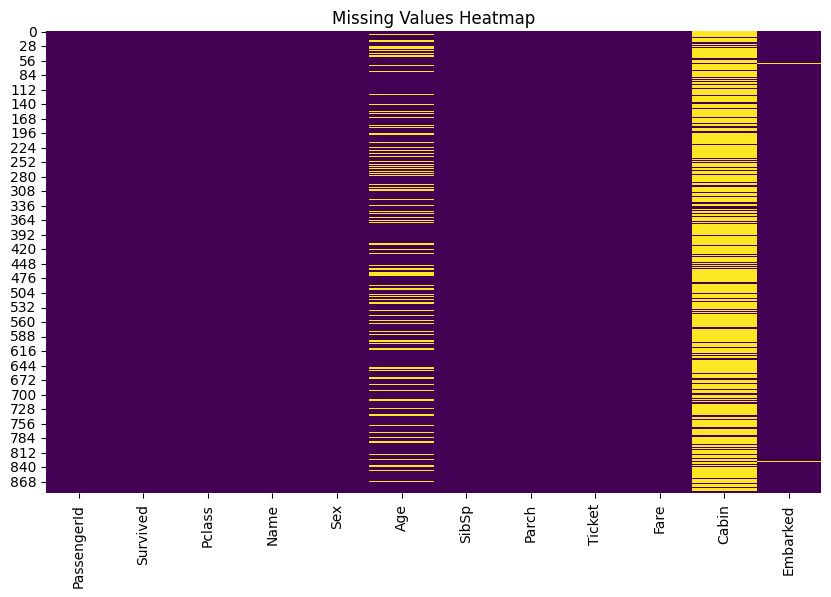


--- EDA: Survival Rate ---
Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


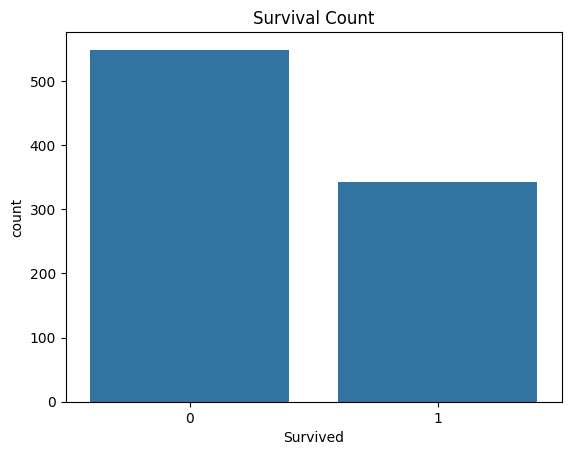


--- EDA: Feature Distributions ---


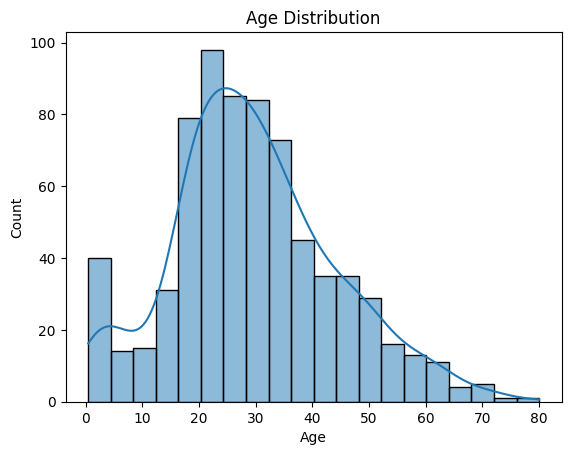

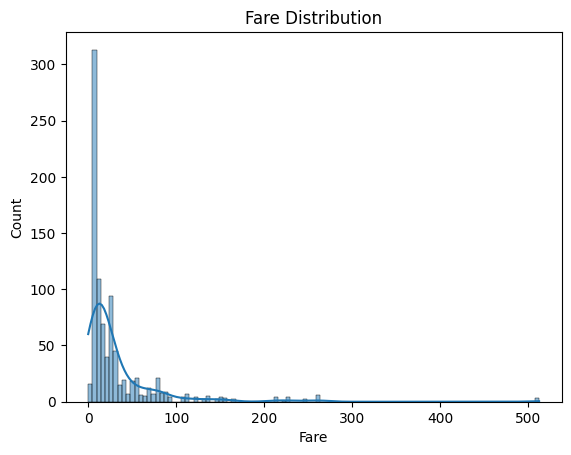

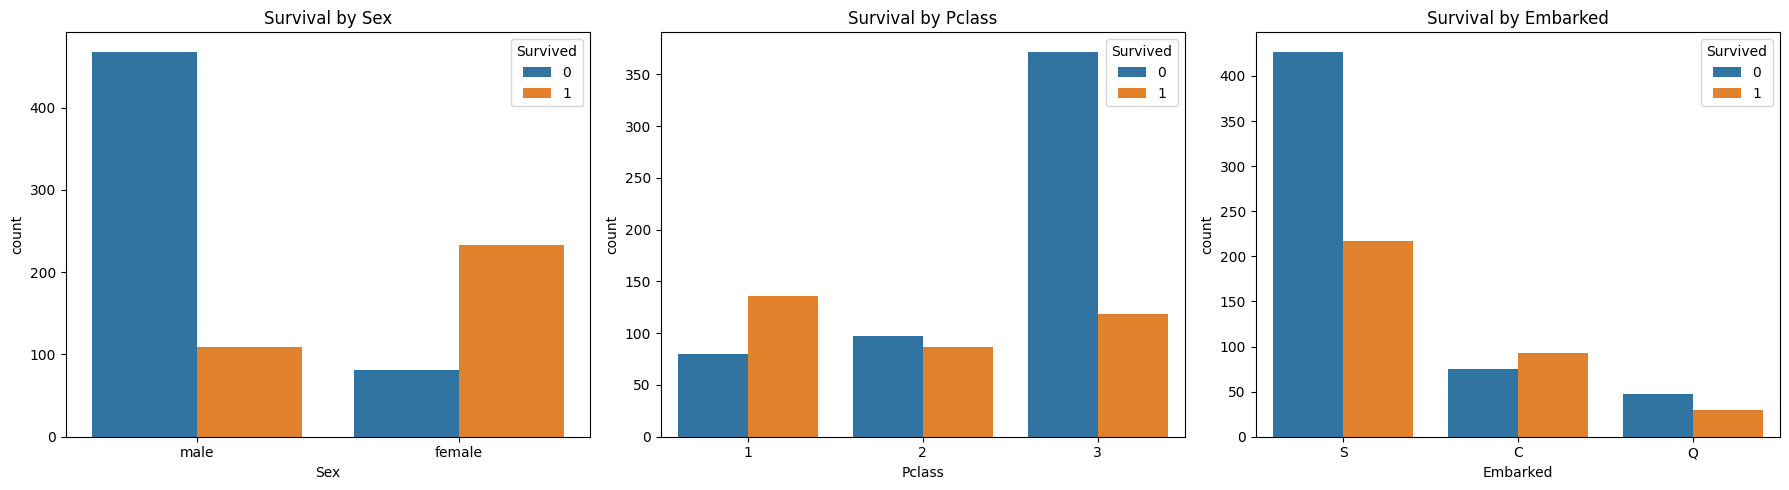

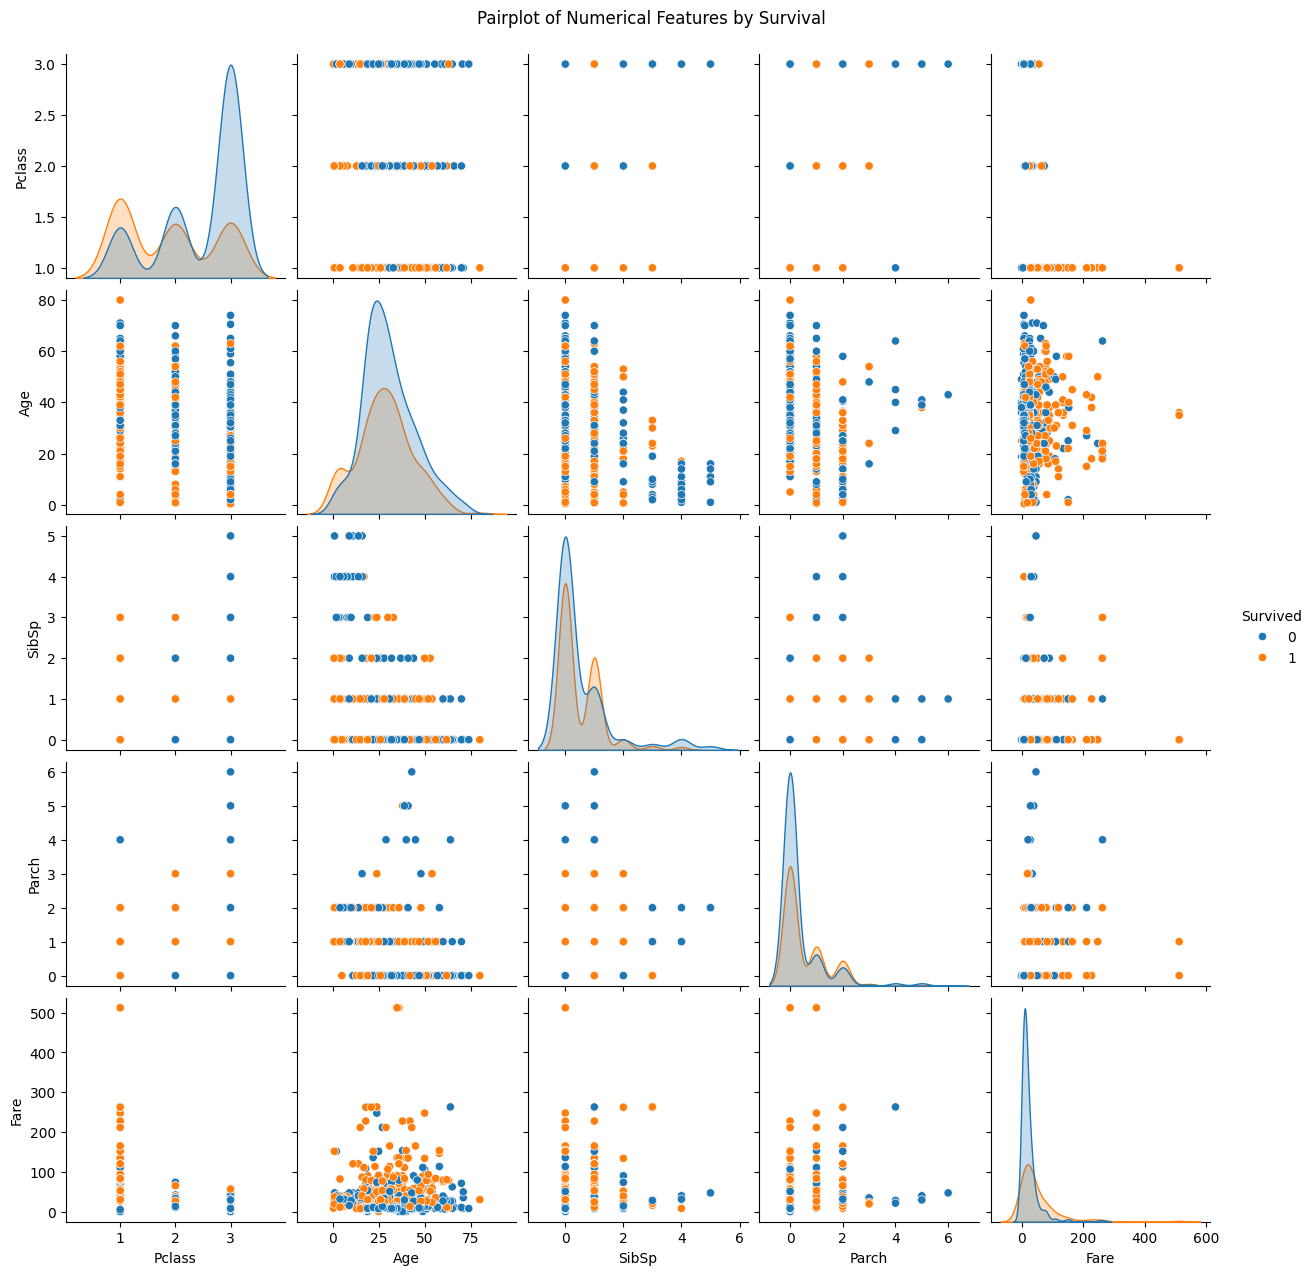

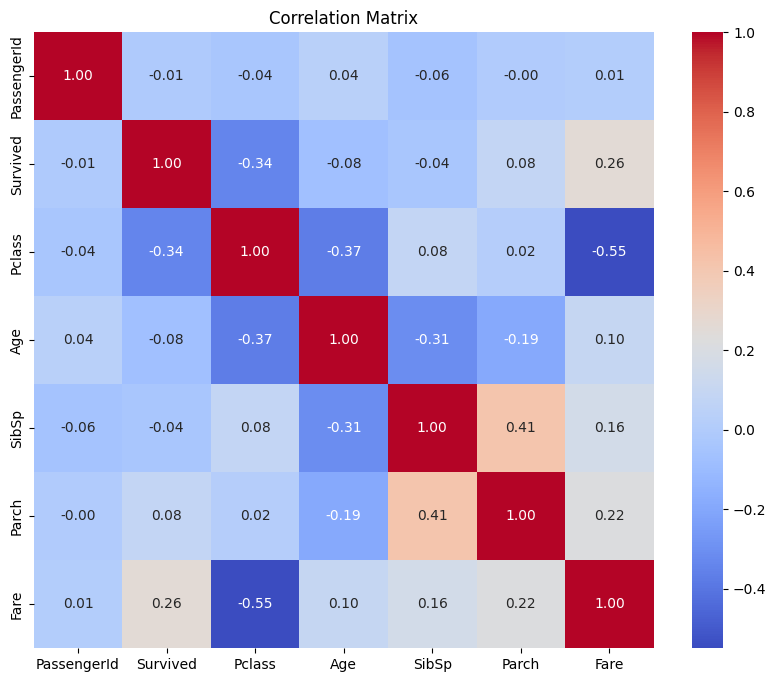

/tmp/ipykernel_524/2382653517.py:77: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].median(), inplace=True)
/tmp/ipykernel_524/2382653517.py:80: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', tr


--- Data after Preprocessing ---
   Survived  Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  \
0         0       3  22.0      1      0   7.2500      True       False   
1         1       1  38.0      1      0  71.2833     False       False   
2         1       3  26.0      0      0   7.9250     False       False   
3         1       1  35.0      1      0  53.1000     False       False   
4         0       3  35.0      0      0   8.0500      True       False   

   Embarked_S  
0        True  
1       False  
2        True  
3        True  
4        True  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Age         891 non-null    float64
 3   SibSp       891 non-null    int64  
 4   Parch       891 non-null    int64  
 5   Fare        891 non-null    f

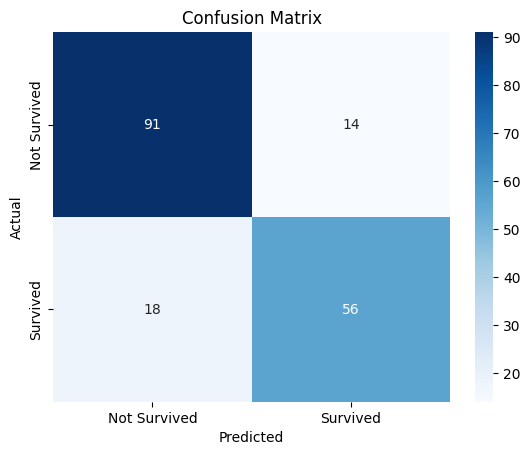

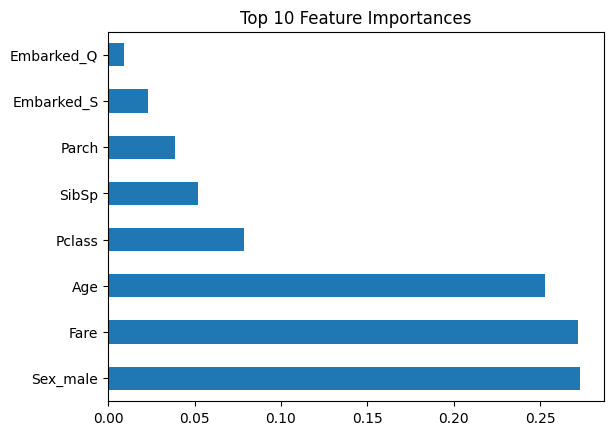

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load the dataset
try:
    df = pd.read_csv('titanic/train.csv')
    print("Dataset loaded successfully from local path 'titanic/train.csv'")
except FileNotFoundError:
    # Fallback to download if not found locally
    print("Dataset not found locally, attempting to download from GitHub...")
    df = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')
    print("Dataset downloaded successfully from GitHub.")

print("\n--- Initial Data Info ---")
print(df.head())
print(df.info())
print(df.describe())

# 2. Exploratory Data Analysis (EDA)
print("\n--- EDA: Missing Values ---")
print(df.isnull().sum())

plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

print("\n--- EDA: Survival Rate ---")
print(df['Survived'].value_counts(normalize=True))
sns.countplot(x='Survived', data=df)
plt.title('Survival Count')
plt.show()

print("\n--- EDA: Feature Distributions ---")
# Age distribution
sns.histplot(df['Age'].dropna(), kde=True)
plt.title('Age Distribution')
plt.show()

# Fare distribution
sns.histplot(df['Fare'], kde=True)
plt.title('Fare Distribution')
plt.show()

# Categorical feature counts vs Survival
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(x='Sex', hue='Survived', data=df, ax=axes[0])
axes[0].set_title('Survival by Sex')
sns.countplot(x='Pclass', hue='Survived', data=df, ax=axes[1])
axes[1].set_title('Survival by Pclass')
sns.countplot(x='Embarked', hue='Survived', data=df, ax=axes[2])
axes[2].set_title('Survival by Embarked')
plt.tight_layout()
plt.show()

# Pairplot for numerical features
sns.pairplot(df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].dropna(), hue='Survived', diag_kind='kde')
plt.suptitle('Pairplot of Numerical Features by Survival', y=1.02)
plt.show()

# Correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

# 3. Feature Engineering and Preprocessing
# Drop 'Cabin' due to too many missing values
df = df.drop('Cabin', axis=1)

# Fill missing 'Age' with median
df['Age'].fillna(df['Age'].median(), inplace=True)

# Fill missing 'Embarked' with mode
df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)

# Drop 'PassengerId' and 'Name' as they are not useful for prediction
df = df.drop(['PassengerId', 'Name', 'Ticket'], axis=1)

# Convert categorical features to numerical using one-hot encoding
df = pd.get_dummies(df, columns=['Sex', 'Embarked'], drop_first=True)

print("\n--- Data after Preprocessing ---")
print(df.head())
print(df.info())

# 4. Model Training (RandomForestClassifier)
# Define features (X) and target (y)
X = df.drop('Survived', axis=1)
y = df['Survived']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nTraining set size: {len(X_train)} samples")
print(f"Test set size: {len(X_test)} samples")

# Initialize and train the RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# 5. Model Evaluation
print("\n--- Model Evaluation ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Survived', 'Survived'], yticklabels=['Not Survived', 'Survived'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Feature Importance
feature_importances = pd.Series(model.feature_importances_, index=X.columns)
feature_importances.nlargest(10).plot(kind='barh')
plt.title('Top 10 Feature Importances')
plt.show()
